# SafeWalk Chicago: predicting where and when street crime happens, and routing around it

**Question:** using 10 years of crime records, can we predict which streets are risky at which time of day, and can a navigation app use that to suggest safer walking routes?

**Data (official City of Chicago open data):**
* 264,434 street crimes, 2015-2024: robbery, battery, assault, sexual assault, homicide, kidnapping, pickpocketing and purse snatching, on streets, sidewalks, alleys, parks, parking lots and public transit. Domestic incidents are excluded because they are not a risk to passers-by.
* The city's street centerline network (56,000 segments), used for walking routes.

**Setup:** the city is split into 250 m x 250 m cells. The week is split into 12 time slots: weekday or weekend, times six 4-hour windows. Each week we predict the next week using only earlier weeks. Models are trained on 2015-2023 and tested on all of 2024.

**How the score works:** rank the city's cells from riskiest to safest, then ask what share of next week's crimes fall inside the top X% of the city. This is the standard metric in crime forecasting; plain "accuracy" is misleading because almost every cell has no crime in a given week.

Runtime: about 10 minutes on a laptop, most of it model training. Requirements: `pip install pandas numpy scipy matplotlib lightgbm networkx`.

## 0. Project modules
These cells write the helper modules to disk, so the steps below stay short.

In [1]:
%%writefile style.py
"""Shared plot style: one sequential blue ramp, fixed categorical order, quiet axes."""
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

SURFACE = "#fcfcfb"
TEXT = "#0b0b0b"
TEXT2 = "#52514e"
GRIDLINE = "#e4e3df"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed order, never cycled
SEQ = ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ)


def apply():
    mpl.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRIDLINE, "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
        "text.color": TEXT, "axes.titlecolor": TEXT, "axes.titleweight": "bold", "axes.titlesize": 12,
        "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRIDLINE, "grid.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
        "lines.linewidth": 2, "legend.frameon": False,
    })

Writing style.py


In [2]:
%%writefile chi.py
"""Chicago street-crime hotspots: data loading, real-world grid, time slots, street network."""
import json, glob
import numpy as np, pandas as pd

CRIME_FILE = "data/chicago_street_crime_2015_2024.csv.gz"
STREET_FILES = "data/streets_*.json"

# ---- real-world grid: local metric projection around Chicago
LON0, LAT0 = -87.95, 41.64
M_PER_DEG_LAT = 110_950.0
M_PER_DEG_LON = 111_320.0 * np.cos(np.radians(41.84))
CELL_M = 250                        # 250 m x 250 m cells
NX, NY = 144, 176                   # 36 km x 44 km covers the whole city

# ---- time: weekly blocks, weekday/weekend x six 4-hour windows = 12 slots
WEEK0 = pd.Timestamp("2014-12-29")  # a Monday
N_WIN = 6
DAYTYPES = ("Weekday", "Weekend")
WIN_LABELS = ["12-4 am", "4-8 am", "8 am-12 pm", "12-4 pm", "4-8 pm", "8 pm-12 am"]


def to_xy(lat, lon):
    return (np.asarray(lon) - LON0) * M_PER_DEG_LON, (np.asarray(lat) - LAT0) * M_PER_DEG_LAT


def to_latlon(x, y):
    return LAT0 + np.asarray(y) / M_PER_DEG_LAT, LON0 + np.asarray(x) / M_PER_DEG_LON


def load_crimes(path=CRIME_FILE):
    df = pd.read_csv(path, parse_dates=["date"])
    df["x"], df["y"] = to_xy(df.latitude, df.longitude)
    df["gx"] = (df.x // CELL_M).astype(int).clip(0, NX - 1)
    df["gy"] = (df.y // CELL_M).astype(int).clip(0, NY - 1)
    df["week"] = (df.date - WEEK0).dt.days // 7
    df["weekend"] = (df.date.dt.dayofweek >= 5).astype(int)
    df["win"] = df.date.dt.hour // 4
    df["year"] = df.date.dt.year
    return df


def week_start(w):
    return WEEK0 + pd.Timedelta(weeks=int(w))


def load_streets(pattern=STREET_FILES):
    """City street centerlines -> list of dicts with node ids, class, name, length (m) and xy polyline."""
    rows = []
    for f in sorted(glob.glob(pattern)):
        rows += json.load(open(f))
    segs = []
    for r in rows:
        g = r.get("the_geom")
        if not g or not r.get("fnode_id"):
            continue
        lines = g["coordinates"] if g["type"] == "MultiLineString" else [g["coordinates"]]
        pts = [p[:2] for line in lines for p in line]
        if len(pts) < 2:
            continue
        lon, lat = np.array(pts, float).T
        x, y = to_xy(lat, lon)
        name = " ".join(s for s in (r.get("pre_dir"), r.get("street_nam"), r.get("street_typ")) if s)
        segs.append(dict(u=r["fnode_id"], v=r["tnode_id"], cls=r.get("class", ""), name=name,
                         length=float(np.hypot(np.diff(x), np.diff(y)).sum()), x=x, y=y))
    return segs


def street_cells(segs, step=25.0):
    """Grid cells crossed by streets (our 'city area' mask) and street length per cell by road class."""
    mask = np.zeros((NY, NX), bool)
    length = {k: np.zeros((NY, NX), np.float32) for k in ("arterial", "local", "all")}
    for s in segs:
        x, y = s["x"], s["y"]
        d = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
        if d[-1] == 0:
            continue
        t = np.arange(0, d[-1] + step, step).clip(max=d[-1])
        px, py = np.interp(t, d, x), np.interp(t, d, y)
        gx = (px // CELL_M).astype(int).clip(0, NX - 1)
        gy = (py // CELL_M).astype(int).clip(0, NY - 1)
        mask[gy, gx] = True
        kind = "arterial" if s["cls"] in ("2", "3") else "local" if s["cls"] == "4" else None
        np.add.at(length["all"], (gy, gx), step)
        if kind:
            np.add.at(length[kind], (gy, gx), step)
    return mask, length

Writing chi.py


In [3]:
%%writefile hotspot.py
"""Weekly hotspot prediction on a 250 m grid for 12 time slots (weekday/weekend x six 4-hour windows).

Everything a prediction for week t uses comes from weeks before t.
"""
import numpy as np, pandas as pd
from scipy.ndimage import gaussian_filter
import chi

N_SLOT = 2 * chi.N_WIN
LOOKBACKS = (1, 4, 13, 52, 156, 260)          # weeks: up to 5 years of history


def count_cube(df, n_weeks):
    C = np.zeros((n_weeks, 2, chi.N_WIN, chi.NY, chi.NX), np.float32)
    ok = df.week.between(0, n_weeks - 1)
    np.add.at(C, (df.week[ok], df.weekend[ok], df.win[ok], df.gy[ok], df.gx[ok]), 1)
    return C


class History:
    """Fast 'incidents per week over the last L weeks' for any target week t, via cumulative sums."""
    def __init__(self, C):
        self.cs = np.concatenate([np.zeros_like(C[:1]), np.cumsum(C, 0, dtype=np.float32)])

    def rate(self, t, L):
        lo = max(t - L, 0)
        return (self.cs[t] - self.cs[lo]) / max(t - lo, 1)

    def window_rate(self, t0, t1):
        """Rate over weeks t0..t1-1 (clipped to available history)."""
        t0, t1 = max(t0, 0), max(t1, 0)
        return (self.cs[t1] - self.cs[t0]) / max(t1 - t0, 1)


def smooth(a, s_space, s_time=0.0):
    """a: (2, 6, NY, NX). Gaussian in space; circular across the six 4-hour windows of the same day type."""
    if s_space == 0 and s_time == 0:
        return a
    return gaussian_filter(a, sigma=(0, s_time, s_space, s_space),
                           mode=("constant", "wrap", "constant", "constant"))


def capture_curve(score, actual, seed=0):
    """Share of actual incidents captured as flagged area grows; ties broken randomly."""
    order = np.lexsort((np.random.default_rng(seed).random(score.size), -score))
    return np.cumsum(actual[order]) / max(actual.sum(), 1)


def evaluate(pred_fn, C, mask, weeks, levels=(0.01, 0.05, 0.2)):
    """pred_fn(t) -> (2, 6, NY, NX) scores. Returns one row per (week, slot) with capture at each level."""
    n = mask.sum()
    rows = []
    for t in weeks:
        P = pred_fn(t)
        for d in range(2):
            for w in range(chi.N_WIN):
                a = C[t, d, w][mask]
                if a.sum() == 0:
                    continue
                cur = capture_curve(P[d, w][mask], a)
                r = dict(week=t, weekend=d, win=w, n=a.sum(), auc=cur.mean())
                for lv in levels:
                    r[f"top{lv*100:g}"] = cur[int(np.ceil(lv * n)) - 1]
                rows.append(r)
    return pd.DataFrame(rows)


def kde_predictor(H, L, s_space, s_time):
    return lambda t: smooth(H.rate(t, L), s_space, s_time)


# ---------------- features for the machine-learning model ----------------
def static_features(street_len):
    xx, yy = np.meshgrid(np.arange(chi.NX), np.arange(chi.NY))
    return {"street_len_all": street_len["all"], "street_len_arterial": street_len["arterial"],
            "street_len_local": street_len["local"], "cell_x": xx.astype(np.float32), "cell_y": yy.astype(np.float32)}


def week_features(H, t, kde_best, static, mask):
    """All features for target week t as (n_slots * n_cells, n_features), plus names."""
    F = {}
    for L in LOOKBACKS:
        r = H.rate(t, L)
        for s in (0, 1, 2):
            F[f"same_slot_{L}w_s{s}"] = smooth(r, s)
        F[f"st_kde_{L}w"] = smooth(r, **kde_best)
    for L in (52, 260):                                     # all times of day and both day types pooled
        allt = H.rate(t, L).sum((0, 1), keepdims=True)
        F[f"any_time_{L}w_s1"] = np.broadcast_to(smooth(allt, 1), (2, chi.N_WIN, chi.NY, chi.NX))
    # same season last year and two years ago (weeks t-54..t-50 and t-106..t-102)
    for k in (1, 2):
        F[f"same_season_{k}y"] = smooth(H.window_rate(t - 52 * k - 2, t - 52 * k + 3), **kde_best)
    names = list(F) + list(static) + ["weekend", "window"]
    cols = []
    for v in F.values():
        cols.append(v[:, :, mask].reshape(-1))
    n_cells = mask.sum()
    for v in static.values():
        cols.append(np.tile(v[mask], N_SLOT))
    d_idx, w_idx = np.meshgrid(np.arange(2), np.arange(chi.N_WIN), indexing="ij")
    cols.append(np.repeat(d_idx.ravel(), n_cells)); cols.append(np.repeat(w_idx.ravel(), n_cells))
    return np.column_stack(cols).astype(np.float32), names


def week_target(C, t, mask):
    return C[t][:, :, mask].reshape(-1)

Writing hotspot.py


In [4]:
%%writefile routing.py
"""Walking graph from Chicago's street centerlines + risk-weighted routing."""
import numpy as np, networkx as nx
import chi

WALKABLE = {"2", "3", "4", "5", "7", "S"}   # drop expressways (1), ramps (9), runways (99), rivers, extensions


def build_graph(segs):
    G = nx.Graph()
    for i, s in enumerate(segs):
        if s["cls"] not in WALKABLE or s["u"] == s["v"] or s["length"] < 1:
            continue
        G.add_node(s["u"], x=s["x"][0], y=s["y"][0])
        G.add_node(s["v"], x=s["x"][-1], y=s["y"][-1])
        if G.has_edge(s["u"], s["v"]) and G[s["u"]][s["v"]]["length"] <= s["length"]:
            continue
        G.add_edge(s["u"], s["v"], length=s["length"], seg=i, name=s["name"])
    biggest = max(nx.connected_components(G), key=len)
    return G.subgraph(biggest).copy()


def sample_along(x, y, step=25.0):
    d = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    t = np.arange(step / 2, max(d[-1], step / 2 + 1e-6), step).clip(max=d[-1])
    return np.interp(t, d, x), np.interp(t, d, y)


def edge_risk(G, segs, risk):
    """risk: (2, 6, NY, NX) predicted incidents per hour per cell. Sets edge['risk'] = (12,) mean along the edge."""
    for u, v, e in G.edges(data=True):
        s = segs[e["seg"]]
        px, py = sample_along(s["x"], s["y"])
        gx = (px // chi.CELL_M).astype(int).clip(0, chi.NX - 1)
        gy = (py // chi.CELL_M).astype(int).clip(0, chi.NY - 1)
        e["risk"] = risk[:, :, gy, gx].mean(-1).reshape(-1).astype(np.float32)
        e["cells"] = np.unique(gy * chi.NX + gx)


def set_weights(G, slot, lam, ref):
    """cost = length x (1 + lam x risk / ref). lam = 0 gives the shortest route."""
    for u, v, e in G.edges(data=True):
        e["w"] = e["length"] * (1 + lam * e["risk"][slot] / ref)


def route(G, a, b):
    return nx.shortest_path(G, a, b, weight="w")


def path_xy(G, segs, path):
    xs, ys = [], []
    for u, v in zip(path[:-1], path[1:]):
        s = segs[G[u][v]["seg"]]
        x, y = s["x"], s["y"]
        if np.hypot(x[0] - G.nodes[u]["x"], y[0] - G.nodes[u]["y"]) > np.hypot(x[-1] - G.nodes[u]["x"], y[-1] - G.nodes[u]["y"]):
            x, y = x[::-1], y[::-1]
        xs.append(x); ys.append(y)
    return np.concatenate(xs), np.concatenate(ys)


def path_stats(G, path, slot):
    L = sum(G[u][v]["length"] for u, v in zip(path[:-1], path[1:]))
    expo = sum(G[u][v]["length"] * G[u][v]["risk"][slot] for u, v in zip(path[:-1], path[1:]))
    return L, expo

Writing routing.py


## 1. Download the data (about 1-2 minutes; skipped if already downloaded)

In [5]:
"""Download 10 years of Chicago street crime + the city's street network from the official open-data portal."""
import os, json, time, urllib.parse, urllib.request
import pandas as pd

os.makedirs("data", exist_ok=True); os.makedirs("out", exist_ok=True)
CRIMES = "https://data.cityofchicago.org/resource/ijzp-q8t2.csv"
STREETS = "https://data.cityofchicago.org/resource/pr57-gg9e.json"

WHERE = (
    "year = {year} AND domestic = false AND latitude IS NOT NULL AND ("
    "primary_type in('ROBBERY','BATTERY','ASSAULT','HOMICIDE','CRIMINAL SEXUAL ASSAULT','CRIM SEXUAL ASSAULT','KIDNAPPING') "
    "OR (primary_type='THEFT' AND description in('POCKET-PICKING','PURSE-SNATCHING'))) AND ("
    "location_description in('STREET','SIDEWALK','ALLEY','PARKING LOT / GARAGE (NON RESIDENTIAL)','PARKING LOT/GARAGE(NON.RESID.)',"
    "'PARK PROPERTY','GAS STATION','VACANT LOT / LAND','VACANT LOT/LAND','BRIDGE','HIGHWAY / EXPRESSWAY','HIGHWAY/EXPRESSWAY',"
    "'LAKEFRONT / WATERFRONT / RIVERBANK','LAKEFRONT/WATERFRONT/RIVERBANK') OR location_description like 'CTA%')"
)


def get(url, params, path, tries=5):
    """Download with retries: the portal sometimes drops long-running requests."""
    req = urllib.request.Request(f"{url}?{urllib.parse.urlencode(params)}", headers={"User-Agent": "safewalk-notebook"})
    for k in range(tries):
        try:
            with urllib.request.urlopen(req, timeout=300) as r:
                data = r.read()
            open(path, "wb").write(data)
            return
        except Exception as e:
            if k == tries - 1:
                raise
            print(f"  retrying after {type(e).__name__} ({k + 1}/{tries - 1})")
            time.sleep(5 * (k + 1))


crime_file = "data/chicago_street_crime_2015_2024.csv.gz"
if not os.path.exists(crime_file):
    parts = []
    for year in range(2015, 2025):                      # one request per year (~27,000 rows each)
        p = f"data/part_{year}.csv"
        get(CRIMES, {"$select": "id,date,primary_type,description,location_description,arrest,latitude,longitude",
                     "$where": WHERE.format(year=year), "$order": "id", "$limit": 100000}, p)
        d = pd.read_csv(p); os.remove(p)
        parts.append(d); print(f"crimes {year}: {len(d)} rows")
    df = pd.concat(parts, ignore_index=True).drop_duplicates("id")
    df = df[df.latitude.between(41.6, 42.1) & df.longitude.between(-87.95, -87.5)]   # drop mis-geocoded points
    df["primary_type"] = df.primary_type.replace({"CRIM SEXUAL ASSAULT": "CRIMINAL SEXUAL ASSAULT"})
    df.to_csv(crime_file, index=False)
print("street crimes:", len(pd.read_csv(crime_file)))

for off in (0, 30000):
    path = f"data/streets_{off}.json"
    if not os.path.exists(path):
        get(STREETS, {"$select": "fnode_id,tnode_id,the_geom,class,street_nam,street_typ,pre_dir,length,status",
                      "$order": "objectid", "$limit": 30000, "$offset": off}, path)
    print(path, len(json.load(open(path))), "street segments")

crimes 2015: 27069 rows


crimes 2016: 30687 rows


crimes 2017: 29621 rows


crimes 2018: 27608 rows


crimes 2019: 25864 rows


...

crimes 2023: 27138 rows


crimes 2024: 26215 rows


street crimes: 264434


data/streets_0.json 30000 street segments


data/streets_30000.json 26338 street segments


## 2. Explore: where, when, and how it changes over time

rows 264434 years 2015 2024
per year {2015: 27069, 2016: 30687, 2017: 29621, 2018: 27608, 2019: 25864, 2020: 22303, 2021: 23371, 2022: 24558, 2023: 27138, 2024: 26215}
share 20:00-04:00: 37.1
weekend share of incidents: 31.1 (2/7 = 28.6 expected if flat)
12-4am incidents per day: weekend 17.8 weekday 9.1
busiest hour 16 quietest 6
{'STREET': 0.406, 'SIDEWALK': 0.321, 'ALLEY': 0.067, 'GAS STATION': 0.037}
cells with any crime 7777 ; top 5% of those cells hold 30.7 % of crime


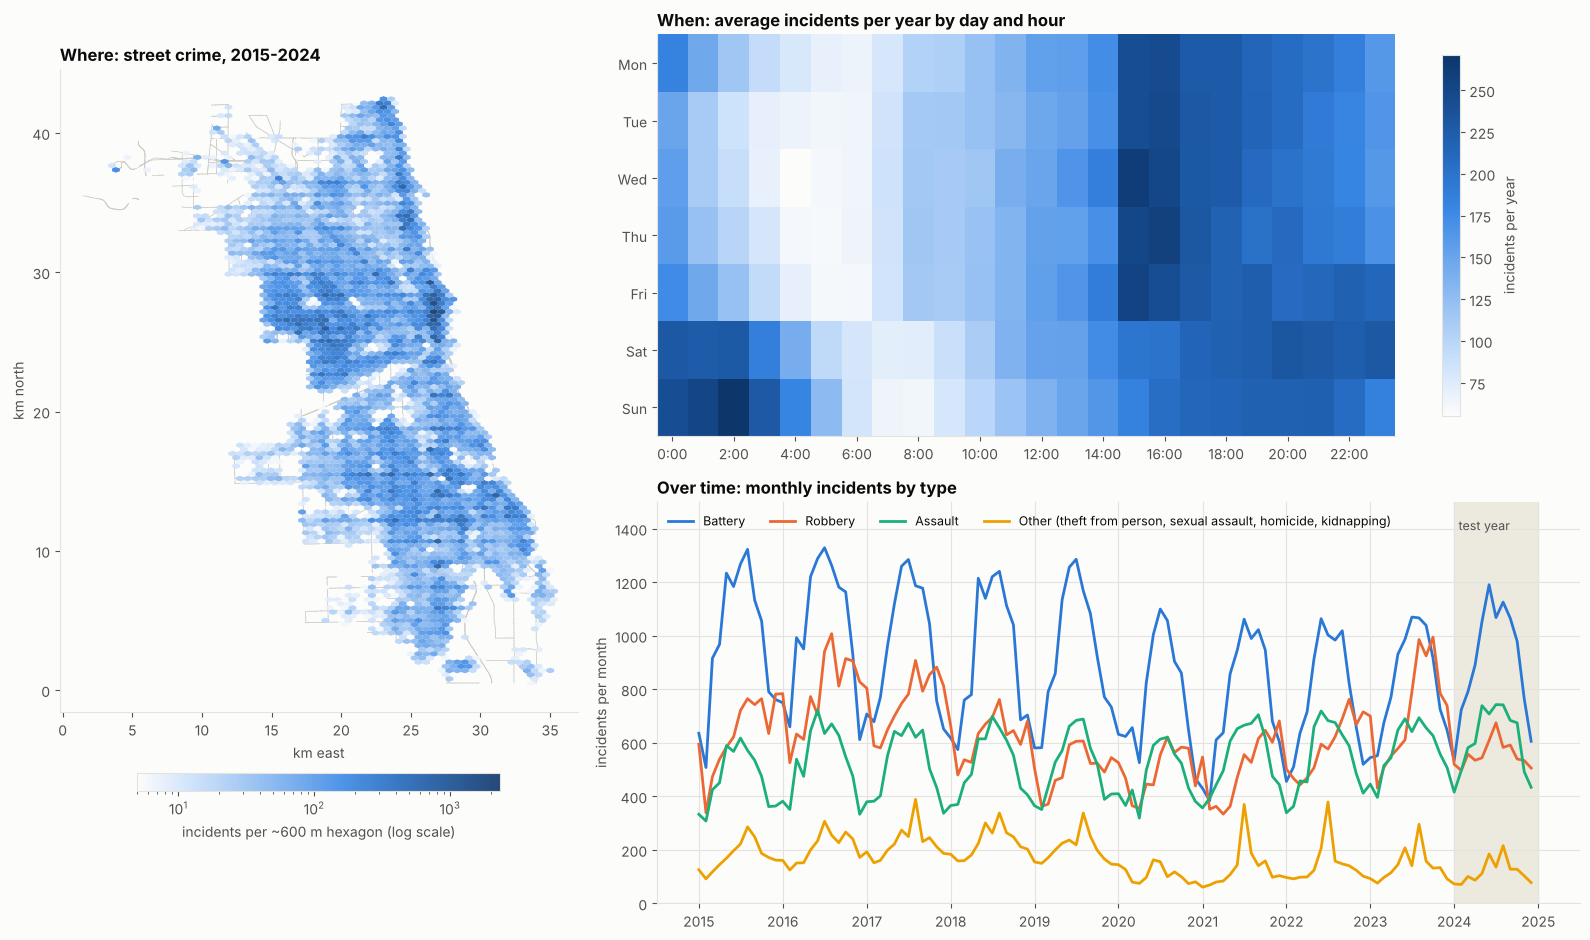

In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import chi, style
style.apply()

df = chi.load_crimes()
segs = chi.load_streets()

fig = plt.figure(figsize=(16, 9.5))
gs = fig.add_gridspec(2, 3, width_ratios=[1.35, 1.1, 1.1], height_ratios=[1, 1])

# where: density on the real map, street network as basemap
ax = fig.add_subplot(gs[:, 0])
for s in segs:
    if s["cls"] in ("1", "2", "3"):
        ax.plot(s["x"] / 1000, s["y"] / 1000, color="#c9c8c2", lw=0.5, zorder=1)
hb = ax.hexbin(df.x / 1000, df.y / 1000, gridsize=(60, 70), bins="log", cmap=style.SEQ_CMAP,
               mincnt=5, linewidths=0, alpha=0.9, zorder=2)
ax.set_aspect("equal"); ax.grid(False)
ax.set_title("Where: street crime, 2015-2024")
ax.set_xlabel("km east"); ax.set_ylabel("km north")
fig.colorbar(hb, ax=ax, orientation="horizontal", shrink=0.7, pad=0.07, label="incidents per ~600 m hexagon (log scale)")

# when: hour x day-of-week heatmap
ax = fig.add_subplot(gs[0, 1:])
hd = df.groupby([df.date.dt.dayofweek, df.date.dt.hour]).size().unstack(fill_value=0) / 10  # per year
im = ax.imshow(hd.values, aspect="auto", cmap=style.SEQ_CMAP, origin="upper")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2), [f"{h}:00" for h in range(0, 24, 2)])
ax.grid(False); ax.set_title("When: average incidents per year by day and hour")
fig.colorbar(im, ax=ax, shrink=0.9, label="incidents per year")

# trend: monthly totals by type
ax = fig.add_subplot(gs[1, 1:])
m = df.set_index("date").groupby("primary_type").resample("MS").size().unstack(0).fillna(0)
top = ["BATTERY", "ROBBERY", "ASSAULT"]
m["OTHER"] = m.drop(columns=top).sum(axis=1)
for col, c in zip(top + ["OTHER"], style.CAT):
    ax.plot(m.index, m[col], color=c, label=col.title() if col != "OTHER" else "Other (theft from person, sexual assault, homicide, kidnapping)")
ax.set_title("Over time: monthly incidents by type")
ax.set_ylabel("incidents per month"); ax.legend(loc="upper left", bbox_to_anchor=(0, 1.0), fontsize=9, ncol=4)
ax.set_ylim(0, 1500)
ax.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31"), color="#ece9df", zorder=0)
ax.text(pd.Timestamp("2024-01-20"), ax.get_ylim()[1] * 0.93, "test year", color=style.TEXT2, fontsize=9)

fig.tight_layout(); fig.savefig("out/01_eda.png", dpi=150)

# numbers quoted in the write-up
h = df.date.dt.hour
print("rows", len(df), "years", df.year.min(), df.year.max())
print("per year", df.groupby("year").size().to_dict())
print("share 20:00-04:00:", round(((h >= 20) | (h < 4)).mean() * 100, 1))
print("weekend share of incidents:", round(df.weekend.mean() * 100, 1), "(2/7 = 28.6 expected if flat)")
wk_night = df[(df.weekend == 1) & ((h < 4))].shape[0] / 2 / 522; wd_night = df[(df.weekend == 0) & (h < 4)].shape[0] / 5 / 522
print("12-4am incidents per day: weekend", round(wk_night, 1), "weekday", round(wd_night, 1))
print("busiest hour", h.value_counts().idxmax(), "quietest", h.value_counts().idxmin())
print(df.location_description.value_counts(normalize=True).head(4).round(3).to_dict())
cell = df.groupby(["gx", "gy"]).size().sort_values(ascending=False)
print("cells with any crime", len(cell), "; top 5% of those cells hold", round(cell.head(int(len(cell) * .05)).sum() / len(df) * 100, 1), "% of crime")
plt.show()

**What this shows**
* Crime is concentrated: the busiest 5% of cells that ever saw a street crime hold about 31% of all incidents.
* Two daily peaks: **weekday 3-5 pm** (around school dismissal) and **weekend nights, midnight to 3 am**. Weekend early mornings (12-4 am) see about twice as many incidents per day as weekday ones.
* A strong **summer peak** every year, a dip in 2020-2021, and recovery since. The 2024 test year looks like a normal year.

## 3. Baselines: kernel density (KDE) hotspot maps, and does a longer history help?
Bandwidths are tuned on Oct-Dec 2023 only; 2024 is never used for any choice.

In [7]:
"""Step 1: KDE baselines. Tune bandwidths on validation weeks (late 2023) and test on 2024.
Also answers: does a longer history (1 vs 5 years) help?"""
import numpy as np, pandas as pd, json, pickle
import chi, hotspot as H_

df = chi.load_crimes()
segs = chi.load_streets()
mask, street_len = chi.street_cells(segs)
n_weeks = int(df.week.max())                     # drop the last partial week (30-31 Dec 2024)
C = H_.count_cube(df, n_weeks)
H = H_.History(C)

wk = lambda d: int((pd.Timestamp(d) - chi.WEEK0).days // 7)
test = list(range(wk("2024-01-01"), n_weeks))
valid = list(range(wk("2023-10-02"), wk("2024-01-01")))
train = list(range(wk("2021-01-04"), wk("2023-10-02")))
print(f"city cells {mask.sum()} (~{mask.sum() * 0.0625:.0f} km2); weeks: train {len(train)}, valid {len(valid)}, test {len(test)}")
print("share of 2024 crimes inside city cells:", round(C[test][..., mask].sum() / C[test].sum(), 4))

rows = []
for L in (52, 156, 260):
    for ss in (0.25, 0.5, 0.75, 1, 2):
        for st in (0, 1, 2, 3, 5):
            r = H_.evaluate(H_.kde_predictor(H, L, ss, st), C, mask, valid)
            rows.append(dict(L=L, s_space=ss, s_time=st, val_auc=r.auc.mean(), val_top5=r.top5.mean()))
tune = pd.DataFrame(rows).sort_values("val_auc", ascending=False)
print(tune.head(6).round(4).to_string())
best_per_L = tune.groupby("L").head(1).set_index("L")
print(best_per_L.round(4))

# test-set results for each history length with its own tuned bandwidth, plus naive baselines
res = {"Last week (as-is)": H_.evaluate(lambda t: H.rate(t, 1), C, mask, test)}
for L, r in best_per_L.iterrows():
    res[f"Tuned KDE, {L // 52} yr history"] = H_.evaluate(H_.kde_predictor(H, L, r.s_space, r.s_time), C, mask, test)
summ = pd.DataFrame({k: v[["top1", "top5", "top20", "auc"]].mean() for k, v in res.items()}).T
print(summ.round(3))

best = tune.iloc[0]
cfg = dict(n_weeks=n_weeks, test=test, valid=valid, train=train,
           kde_best=dict(s_space=float(best.s_space), s_time=float(best.s_time)), kde_best_L=int(best.L),
           city_cells=int(mask.sum()))
json.dump(cfg, open("out/config.json", "w"), indent=1)
tune.to_csv("out/kde_tuning.csv", index=False)
pickle.dump(res, open("out/kde_results.pkl", "wb"))
np.save("out/mask.npy", mask); pickle.dump(street_len, open("out/street_len.pkl", "wb"))

city cells 9128 (~570 km2); weeks: train 143, valid 13, test 52
share of 2024 crimes inside city cells: 1.0


      L  s_space  s_time  val_auc  val_top5
54  260     0.25       5   0.8103    0.2976
57  260     0.50       2   0.8102    0.2909
58  260     0.50       3   0.8099    0.2892
59  260     0.50       5   0.8098    0.2886
32  156     0.50       2   0.8093    0.2881
52  260     0.25       2   0.8092    0.3005
     s_space  s_time  val_auc  val_top5
L                                      
260     0.25       5   0.8103    0.2976
156     0.50       2   0.8093    0.2881
52      0.50       2   0.7971    0.2887


                          top1   top5  top20    auc
Last week (as-is)        0.031  0.066  0.217  0.512
Tuned KDE, 5 yr history  0.146  0.337  0.657  0.819
Tuned KDE, 3 yr history  0.145  0.332  0.652  0.816
Tuned KDE, 1 yr history  0.145  0.326  0.633  0.804


**Result:** naive "last week's spots" captures only about 22% of crimes in the riskiest 20% of the city, barely better than random. A tuned KDE does far better. **The 10 years of data do help**: a 5-year history beats a 1-year history (about 66% vs 63% in the riskiest 20%), because a single year is too noisy at street level. The best settings are a small spatial bandwidth and a wide time bandwidth: *where* crime happens is stable across the day, while *how much* changes by hour.

## 4. Machine-learning model (LightGBM, about 5 minutes)
Features, all from past weeks only: crime rates over the last 1, 4, 13, 52, 156 and 260 weeks at several spatial smoothing levels; the same season in the last two years; the tuned KDE signals; street length by road type in each cell; and the time slot.

In [8]:
"""Step 2: LightGBM hotspot model. Train on 2021-Sep 2023 targets, early-stop on Oct-Dec 2023, test on 2024."""
import numpy as np, pandas as pd, json, pickle, lightgbm as lgb
import chi, hotspot as H_

cfg = json.load(open("out/config.json"))
df = chi.load_crimes()
mask = np.load("out/mask.npy"); street_len = pickle.load(open("out/street_len.pkl", "rb"))
C = H_.count_cube(df, cfg["n_weeks"]); H = H_.History(C)
static = H_.static_features(street_len)
kde_best = cfg["kde_best"]
rng = np.random.default_rng(0)
KEEP_ZERO = 0.08


def build(weeks, subsample):
    Xs, ys, ws = [], [], []
    for t in weeks:
        X, names = H_.week_features(H, t, kde_best, static, mask)
        y = H_.week_target(C, t, mask)
        if subsample:
            keep = (y > 0) | (rng.random(y.size) < KEEP_ZERO)
            X, y = X[keep], y[keep]
            ws.append(np.where(y > 0, 1.0, 1 / KEEP_ZERO))
        Xs.append(X); ys.append(y)
    return np.vstack(Xs), np.concatenate(ys), (np.concatenate(ws) if subsample else None), names


Xtr, ytr, wtr, names = build(cfg["train"], True)
Xva, yva, _, _ = build(cfg["valid"], False)
print("train rows", len(ytr), "valid rows", len(yva), "features", len(names))
params = dict(objective="poisson", learning_rate=0.05, num_leaves=63, min_data_in_leaf=300,
              feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1, lambda_l2=2.0, verbose=-1, seed=0, num_threads=2)
m = lgb.train(params, lgb.Dataset(Xtr, ytr, weight=wtr, feature_name=names), 3000,
              valid_sets=[lgb.Dataset(Xva, yva, feature_name=names)],
              callbacks=[lgb.early_stopping(150, verbose=False)])
best_iter = m.best_iteration
print("best iteration", best_iter)

# refit on train + valid weeks with the chosen number of rounds
Xa, ya, wa, _ = build(cfg["train"] + cfg["valid"], True)
m = lgb.train(params, lgb.Dataset(Xa, ya, weight=wa, feature_name=names), best_iter)
m.save_model("out/lgbm_chicago.txt")
del Xtr, Xva, Xa

n_cells = mask.sum()
preds = {}
def lgb_pred(t):
    X, _ = H_.week_features(H, t, kde_best, static, mask)
    p = m.predict(X).reshape(2, chi.N_WIN, n_cells)
    out = np.zeros((2, chi.N_WIN, chi.NY, chi.NX), np.float32); out[:, :, mask] = p
    preds[t] = p.astype(np.float32)
    return out

res = pickle.load(open("out/kde_results.pkl", "rb"))
res["LightGBM (ours)"] = H_.evaluate(lgb_pred, C, mask, cfg["test"])
np.save("out/pred_2024.npy", np.stack([preds[t] for t in cfg["test"]]))   # (weeks, 2, 6, cells)
pickle.dump(res, open("out/all_results.pkl", "wb"))

summ = pd.DataFrame({k: v[["top1", "top5", "top20", "auc"]].mean() for k, v in res.items()}).T
print(summ.round(3)); summ.to_csv("out/summary.csv")
kde_name = "Tuned KDE, 5 yr history"
for col in ("top1", "top5", "top20", "auc"):
    a = res["LightGBM (ours)"].groupby("week")[col].mean(); b = res[kde_name].groupby("week")[col].mean()
    print(f"{col}: LightGBM better in {(a > b).sum()}/{len(a)} test weeks, mean gain {100 * (a - b).mean():+.2f} pts")
imp = pd.Series(m.feature_importance("gain"), index=names).sort_values(ascending=False)
imp.to_csv("out/feature_importance.csv"); print((imp / imp.sum() * 100).head(10).round(1))

train rows 1314404 valid rows 1423968 features 35


best iteration 579


                          top1   top5  top20    auc
Last week (as-is)        0.031  0.066  0.217  0.512
Tuned KDE, 5 yr history  0.146  0.337  0.657  0.819
Tuned KDE, 3 yr history  0.145  0.332  0.652  0.816
Tuned KDE, 1 yr history  0.145  0.326  0.633  0.804
LightGBM (ours)          0.149  0.338  0.661  0.822
top1: LightGBM better in 34/52 test weeks, mean gain +0.39 pts
top5: LightGBM better in 26/52 test weeks, mean gain +0.12 pts
top20: LightGBM better in 31/52 test weeks, mean gain +0.44 pts
auc: LightGBM better in 39/52 test weeks, mean gain +0.32 pts
st_kde_260w          42.5
same_slot_260w_s0    17.7
st_kde_156w          12.2
same_slot_156w_s0     2.6
same_slot_260w_s1     2.1
st_kde_52w            1.5
same_slot_13w_s2      1.5
window                1.4
same_season_2y        1.2
st_kde_13w            1.1
dtype: float64


map week 2024-07-15 crimes 55 in top5 36.4 in top20 72.7


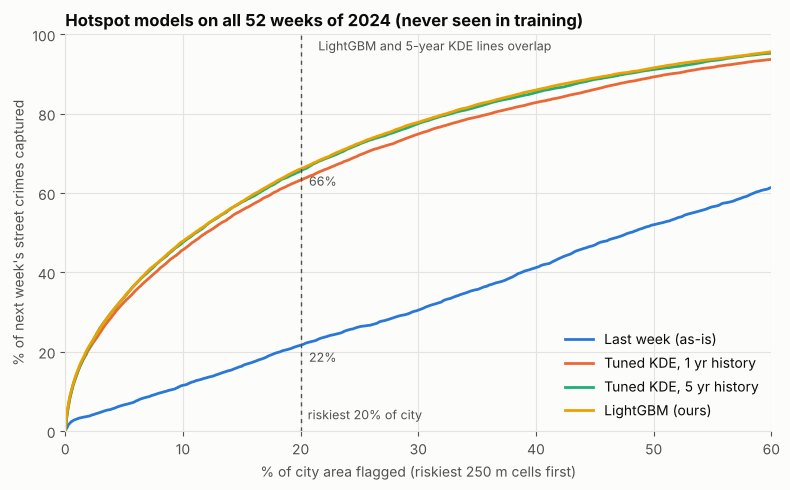

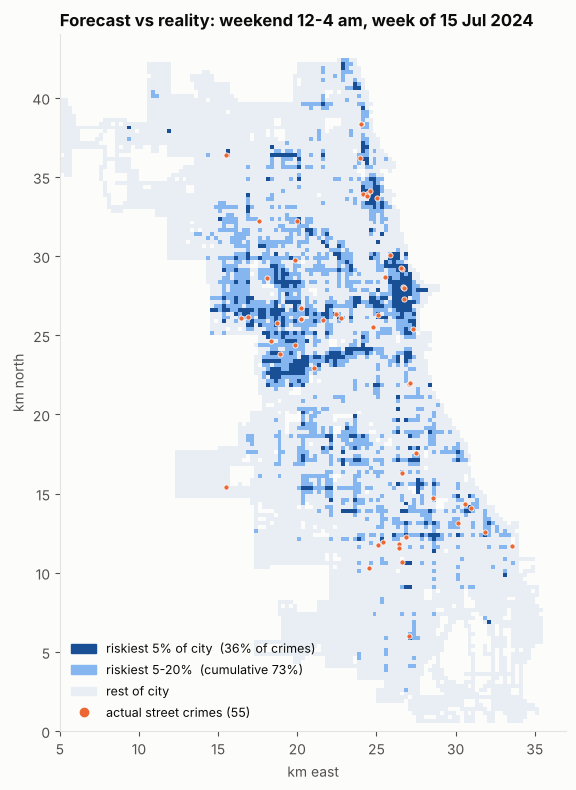

In [9]:
"""Model comparison on 2024 + one predicted hotspot map with that week's real crimes."""
import numpy as np, pandas as pd, json, pickle, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import chi, hotspot as H_, style
style.apply()

cfg = json.load(open("out/config.json")); mask = np.load("out/mask.npy")
df = chi.load_crimes(); C = H_.count_cube(df, cfg["n_weeks"]); H = H_.History(C)
pred = np.load("out/pred_2024.npy")                     # (weeks, 2, 6, cells)
test = cfg["test"]; n = mask.sum()
kb = cfg["kde_best"]

models = {"Last week (as-is)": lambda t: H.rate(t, 1)[:, :, mask],
          "Tuned KDE, 1 yr history": lambda t: H_.smooth(H.rate(t, 52), 0.5, 2)[:, :, mask],
          "Tuned KDE, 5 yr history": lambda t: H_.smooth(H.rate(t, 260), **kb)[:, :, mask],
          "LightGBM (ours)": lambda t: pred[test.index(t)]}
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(1, n + 1) / n * 100
for (name, f), col in zip(models.items(), style.CAT):
    curves = []
    for t in test:
        P = f(t)
        for d in range(2):
            for w in range(chi.N_WIN):
                a = C[t, d, w][mask]
                if a.sum():
                    curves.append(H_.capture_curve(P[d, w], a))
    y = np.mean(curves, 0) * 100
    ax.plot(x, y, color=col, label=name)
    if name in ("LightGBM (ours)", "Last week (as-is)"):
        i = np.searchsorted(x, 20); ax.annotate(f"{y[i]:.0f}%", (20, y[i]), xytext=(6, -12), textcoords="offset points", color=style.TEXT2, fontsize=9)
ax.axvline(20, color=style.TEXT2, lw=1, ls=(0, (3, 3))); ax.text(20.6, 3, "riskiest 20% of city", color=style.TEXT2, fontsize=9)
ax.text(21.5, 96, "LightGBM and 5-year KDE lines overlap", color=style.TEXT2, fontsize=9)
ax.set_xlim(0, 60); ax.set_ylim(0, 100)
ax.set_xlabel("% of city area flagged (riskiest 250 m cells first)"); ax.set_ylabel("% of next week's street crimes captured")
ax.set_title("Hotspot models on all 52 weeks of 2024 (never seen in training)"); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig("out/02_capture_curves.png", dpi=150)

# hotspot map: a summer weekend night in 2024
wk = int((pd.Timestamp("2024-07-15") - chi.WEEK0).days // 7); d, w = 1, 0
p = np.full((chi.NY, chi.NX), np.nan); p[mask] = pred[test.index(wk)][d, w]
v = p[mask]; t5, t20 = np.quantile(v, 0.95), np.quantile(v, 0.80)
cls = np.full(p.shape, np.nan); cls[mask] = 0; cls[mask & (p >= t20)] = 1; cls[mask & (p >= t5)] = 2
ev = df[(df.week == wk) & (df.weekend == d) & (df.win == w)]
in5 = (cls[ev.gy, ev.gx] == 2).mean() * 100; in20 = (cls[ev.gy, ev.gx] >= 1).mean() * 100
fig, ax = plt.subplots(figsize=(7, 8))
ax.imshow(cls, origin="lower", extent=(0, chi.NX * chi.CELL_M / 1000, 0, chi.NY * chi.CELL_M / 1000),
          cmap=ListedColormap(["#e9eef5", "#86b6ef", "#184f95"]), vmin=0, vmax=2, interpolation="nearest")
ax.scatter(ev.x / 1000, ev.y / 1000, s=14, color=style.CAT[1], edgecolor=style.SURFACE, linewidth=0.6, zorder=3)
ax.legend(handles=[Patch(color="#184f95", label=f"riskiest 5% of city  ({in5:.0f}% of crimes)"),
                   Patch(color="#86b6ef", label=f"riskiest 5-20%  (cumulative {in20:.0f}%)"),
                   Patch(color="#e9eef5", label="rest of city"),
                   plt.Line2D([], [], marker="o", ls="", color=style.CAT[1], label=f"actual street crimes ({len(ev)})")],
          loc="lower left", fontsize=9)
ax.set_title(f"Forecast vs reality: weekend 12-4 am, week of {chi.week_start(wk):%-d %b %Y}")
ax.set_xlabel("km east"); ax.set_ylabel("km north"); ax.grid(False)
ax.set_xlim(5, 37); ax.set_ylim(0, 44)
fig.tight_layout(); fig.savefig("out/03_hotspot_map.png", dpi=150)
print("map week", chi.week_start(wk).date(), "crimes", len(ev), "in top5", round(in5, 1), "in top20", round(in20, 1))
plt.show()

**Result:** LightGBM is slightly better than the best KDE (better on overall ranking in about 3 of every 4 test weeks), but only by a fraction of a percentage point. The feature importances show why: long-history crime rates carry almost all the signal. Street crime locations are very stable, so a carefully tuned classical method is already close to the ceiling. Saying this plainly is a stronger result than claiming a big accuracy gain.

## 5. Does it help people? Safer routes vs shortest routes
We build a walking graph from the city's streets (expressways, ramps and runways removed), give every street the risk of the cells it passes through, and route with cost = length x (1 + level x risk / city average). The **risk map uses only 2015-2023 data**, and we count the **real 2024 crimes within 50 m** of each route on 250 random 1-4 km walks. Two risk-blind detours of similar length are the controls: avoiding main roads, and random detours.

In [10]:
"""Step 3: do 'safest' routes (risk predicted only from past data) actually pass fewer real 2024 crimes?"""
import numpy as np, pandas as pd, json, pickle, time
from scipy.spatial import cKDTree
import chi, hotspot as H_, routing as R

cfg = json.load(open("out/config.json"))
mask = np.load("out/mask.npy")
segs = chi.load_streets()
G = R.build_graph(segs)
print("walking graph:", G.number_of_nodes(), "junctions,", G.number_of_edges(), "street segments,",
      round(sum(e["length"] for _, _, e in G.edges(data=True)) / 1000), "km")

# risk map built ONLY from 2015-2023 data: the model's forecast for the first week of 2024, per hour per cell
pred = np.load("out/pred_2024.npy")[0]                             # (2, 6, cells), incidents per week
hours = np.array([20.0, 8.0])[:, None, None]                       # weekday slot = 5 days x 4 h; weekend = 2 x 4 h
risk = np.zeros((2, chi.N_WIN, chi.NY, chi.NX), np.float32); risk[:, :, mask] = pred / hours
R.edge_risk(G, segs, risk)

df = chi.load_crimes(); d24 = df[df.year == 2024]
nodes = np.array(list(G.nodes)); xy = np.array([[G.nodes[n]["x"], G.nodes[n]["y"]] for n in nodes])
rng = np.random.default_rng(1)
pairs = []
while len(pairs) < 250:
    i, j = rng.integers(len(nodes), size=2)
    if 1000 <= np.hypot(*(xy[i] - xy[j])) <= 4000:
        pairs.append((nodes[i], nodes[j]))

SLOTS = {"Weekday 8 pm-12 am": 5, "Weekend 12-4 am": 6 + 0}
LAMS = (0, 0.25, 0.5, 1, 2, 4, 8)
rows = []
t0 = time.time()
for sname, slot in SLOTS.items():
    d, w = divmod(slot, 6)
    pts = d24[(d24.weekend == d) & (d24.win == w)][["x", "y"]].to_numpy()
    tree = cKDTree(pts)
    lens = np.array([e["length"] for _, _, e in G.edges(data=True)])
    rk = np.array([e["risk"][slot] for _, _, e in G.edges(data=True)])
    ref = (lens * rk).sum() / lens.sum()                           # city-average risk per metre of street
    variants = [("Risk-aware (ours)", lam) for lam in LAMS] + \
               [("Avoid main roads", mu) for mu in (0.25, 0.5, 1, 2)] + [("Random detour", a) for a in (0.3, 1, 2, 4)]
    noise = np.random.default_rng(7).random(G.number_of_edges())
    for method, k_ in variants:
        if method == "Risk-aware (ours)":
            R.set_weights(G, slot, k_, ref)
        else:
            for (u, v, e), z in zip(G.edges(data=True), noise):
                bump = (segs[e["seg"]]["cls"] in ("2", "3")) if method == "Avoid main roads" else z
                e["w"] = e["length"] * (1 + k_ * bump)
        for k, (a, b) in enumerate(pairs):
            p = R.route(G, a, b)
            L, expo = R.path_stats(G, p, slot)
            px, py = R.path_xy(G, segs, p)
            sx, sy = R.sample_along(px, py, 20)
            near = set().union(*tree.query_ball_point(np.c_[sx, sy], 50)) if len(sx) else set()
            rows.append(dict(slot=sname, method=method, lam=k_, pair=k, length=L, exposure=expo, crimes_2024=len(near)))
    print(sname, "done", round(time.time() - t0), "s")

r = pd.DataFrame(rows)
r.to_csv("out/route_eval.csv", index=False)
base = r[(r.method == "Risk-aware (ours)") & (r.lam == 0)].set_index(["slot", "pair"])
r = r.join(base[["length", "exposure", "crimes_2024"]], on=["slot", "pair"], rsuffix="_short")
r["extra_dist_pct"] = (r.length / r.length_short - 1) * 100
r["changed"] = r.extra_dist_pct > 0.5
summ = r.groupby(["slot", "method", "lam"]).agg(
    trips_rerouted_pct=("changed", lambda s: s.mean() * 100),
    extra_distance_pct=("extra_dist_pct", "mean"),
    km=("length", lambda s: s.sum() / 1000),
    crimes_2024=("crimes_2024", "sum"),
    crimes_2024_short=("crimes_2024_short", "sum"),
    predicted_exposure=("exposure", "sum"), predicted_exposure_short=("exposure_short", "sum"))
summ["predicted_risk_cut_pct"] = (1 - summ.predicted_exposure / summ.predicted_exposure_short) * 100
summ["real_2024_crimes_cut_pct"] = (1 - summ.crimes_2024 / summ.crimes_2024_short) * 100
summ["real_crimes_per_km"] = summ.crimes_2024 / summ.km
cols = ["trips_rerouted_pct", "extra_distance_pct", "predicted_risk_cut_pct", "real_2024_crimes_cut_pct", "real_crimes_per_km"]
print(summ[cols].round(1).to_string())
summ.to_csv("out/route_summary.csv")
pickle.dump(dict(pairs=pairs), open("out/route_pairs.pkl", "wb"))

walking graph: 33168 junctions, 51096 street segments, 6406 km


Weekday 8 pm-12 am done 12 s


Weekend 12-4 am done 24 s
                                           trips_rerouted_pct  extra_distance_pct  predicted_risk_cut_pct  real_2024_crimes_cut_pct  real_crimes_per_km
slot               method            lam                                                                                                               
Weekday 8 pm-12 am Avoid main roads  0.25                50.8                 2.2                3.600000                      15.9                 1.0
                                     0.50                68.8                 4.9                4.100000                      19.8                 0.9
                                     1.00                76.4                 7.8                2.000000                      20.7                 0.9
                                     2.00                79.6                11.7               -2.700000                      14.7                 0.9
                   Random detour     0.30                29.2 

                  slot             method  lam  extra_dist  crime_cut  ci_lo  ci_hi
0   Weekday 8 pm-12 am   Avoid main roads  0.2         2.2       15.9    8.5   22.9
1   Weekday 8 pm-12 am   Avoid main roads  0.5         4.9       19.8   12.4   27.3
2   Weekday 8 pm-12 am   Avoid main roads  1.0         7.8       20.7   11.2   29.6
3   Weekday 8 pm-12 am   Avoid main roads  2.0        11.7       14.7    2.7   25.5
4   Weekday 8 pm-12 am      Random detour  0.3         0.4        0.7   -6.7    7.7
5   Weekday 8 pm-12 am      Random detour  1.0         1.9        3.1   -4.5   10.4
6   Weekday 8 pm-12 am      Random detour  2.0         3.7        1.8   -7.5   10.5
7   Weekday 8 pm-12 am      Random detour  4.0         6.4        2.4   -6.3   11.6
8   Weekday 8 pm-12 am  Risk-aware (ours)  0.0         0.0        0.0    0.0    0.0
9   Weekday 8 pm-12 am  Risk-aware (ours)  0.2         2.1       39.3   32.3   45.8
10  Weekday 8 pm-12 am  Risk-aware (ours)  0.5         3.5       44.1   37.3

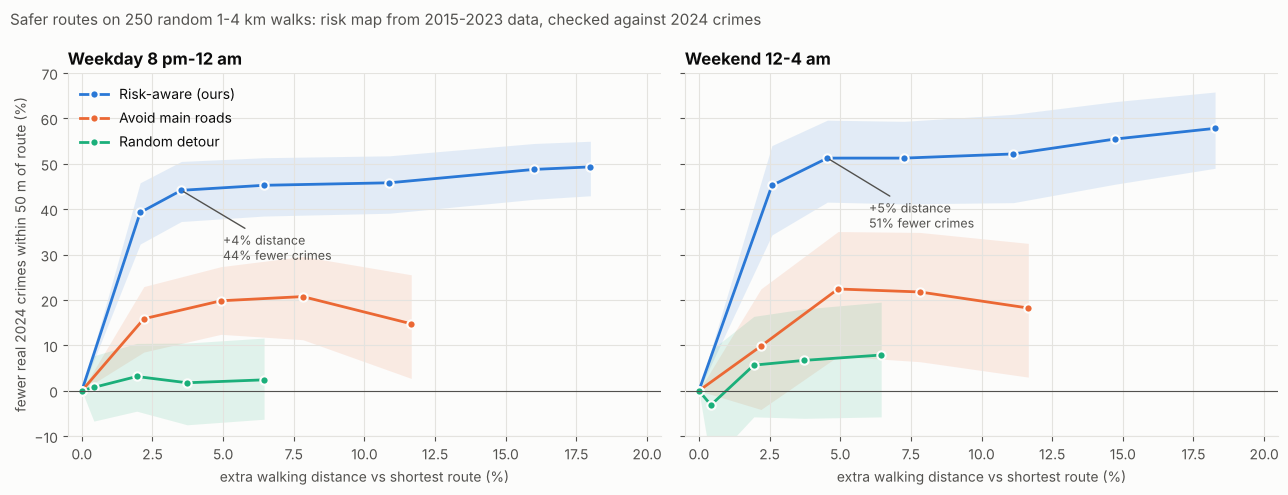

In [11]:
"""Route trade-off chart + bootstrap confidence intervals for the headline numbers."""
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import style
style.apply()

r = pd.read_csv("out/route_eval.csv")
base = r[(r.method == "Risk-aware (ours)") & (r.lam == 0)].set_index(["slot", "pair"])
r = r.join(base[["length", "crimes_2024"]], on=["slot", "pair"], rsuffix="_short")
rng = np.random.default_rng(0)


def stats(g, boot=2000):
    """Extra distance % (mean over trips) and real-crime cut % (ratio of totals), with 95% bootstrap CIs over trips."""
    L, Ls, c, cs = (g[k].to_numpy() for k in ("length", "length_short", "crimes_2024", "crimes_2024_short"))
    ext = (L / Ls - 1) * 100
    cut = (1 - c.sum() / cs.sum()) * 100
    idx = rng.integers(len(g), size=(boot, len(g)))
    cut_b = (1 - c[idx].sum(1) / cs[idx].sum(1)) * 100
    return ext.mean(), cut, *np.percentile(cut_b, [2.5, 97.5])


rows = []
for (slot, method, lam), g in r.groupby(["slot", "method", "lam"]):
    e, c, lo, hi = stats(g)
    rows.append(dict(slot=slot, method=method, lam=lam, extra_dist=e, crime_cut=c, ci_lo=lo, ci_hi=hi))
s = pd.DataFrame(rows)
s.to_csv("out/route_tradeoff.csv", index=False)
print(s.round(1).to_string())

order = ["Risk-aware (ours)", "Avoid main roads", "Random detour"]
colors = dict(zip(order, style.CAT[:3]))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, slot in zip(axes, ["Weekday 8 pm-12 am", "Weekend 12-4 am"]):
    for m in order:
        d = s[(s.slot == slot) & ((s.method == m) | ((s.method == "Risk-aware (ours)") & (s.lam == 0)))].sort_values("extra_dist")
        ax.plot(d.extra_dist, d.crime_cut, "-o", color=colors[m], ms=6, label=m,
                markeredgecolor=style.SURFACE, markeredgewidth=1.5)
        ax.fill_between(d.extra_dist, d.ci_lo, d.ci_hi, color=colors[m], alpha=0.12, linewidth=0)
    pick = s[(s.slot == slot) & (s.method == "Risk-aware (ours)") & (s.lam == 0.5)].iloc[0]
    ax.annotate(f"+{pick.extra_dist:.0f}% distance\n{pick.crime_cut:.0f}% fewer crimes", (pick.extra_dist, pick.crime_cut),
                xytext=(30, -50), textcoords="offset points", color=style.TEXT2, fontsize=9,
                arrowprops=dict(arrowstyle="-", color=style.TEXT2))
    ax.axhline(0, color=style.TEXT2, lw=0.8)
    ax.set_title(slot); ax.set_xlabel("extra walking distance vs shortest route (%)")
    ax.set_xlim(-0.5, 20.5); ax.set_ylim(-10, 70)
axes[0].set_ylabel("fewer real 2024 crimes within 50 m of route (%)")
axes[0].legend(loc="upper left")
fig.suptitle("Safer routes on 250 random 1-4 km walks: risk map from 2015-2023 data, checked against 2024 crimes",
             x=0.01, ha="left", fontsize=11, color=style.TEXT2)
fig.tight_layout(); fig.savefig("out/04_route_tradeoff.png", dpi=150)
plt.show()

**Result:** at the Balanced setting, safer routes are about **4-5% longer** and pass **44-51% fewer real 2024 crimes** (95% bootstrap intervals roughly 37-60%). Avoiding main roads for a similar extra distance gives only about 20%, and random detours give about nothing. So the model's risk map, not just the act of detouring, is what makes routes safer.

## 6. Build the demo app
Packages the street graph and the forecast for the week after the data ends into a single HTML page (`out/safewalk_chicago.html`). Open it in any browser: pick a time slot and safety level, then click a start and a destination.

In [12]:
%%writefile app_template.html
<title>SafeWalk Chicago</title>
<meta name="claude:viewport-fit-sides" content="cover">
<link rel="preconnect" href="https://fonts.googleapis.com">
<link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
<link rel="stylesheet" href="https://fonts.googleapis.com/css2?family=Archivo:wght@400;500;600;700;800&family=IBM+Plex+Mono:wght@400;500&display=swap">
<style>
/* Layout: control rail on the left (stacked under the map on phones), the street map fills the rest. */
:root {
  --bg: #f3f5f7; --panel: #ffffff; --ink: #121820; --ink-2: #4a5562; --ink-3: #7b8692; --line: #dde2e7;
  --map: #eaeef1; --street: #c4ccd3; --street-major: #aab4bd;
  --risk-1: #f2b26a; --risk-2: #e2702b; --risk-3: #b53b16;
  --safe: #1d67c9; --safe-halo: #ffffff; --direct: #2b333c;
  --warn-bg: #fff3e8; --warn-line: #e2702b; --ok-bg: #edf5ec; --ok-line: #3f8a3a;
  --chip: #eef1f4; --chip-on: #121820; --chip-on-ink: #ffffff;
  --label: #5c6773; --lake: #6f8fae;
  --f-display: "Archivo", "Helvetica Neue", Arial, sans-serif;
  --f-body: "Archivo", "Helvetica Neue", Arial, sans-serif;
  --f-mono: "IBM Plex Mono", ui-monospace, "SFMono-Regular", Menlo, monospace;
}
@media (prefers-color-scheme: dark) { :root:not([data-theme="light"]) {
  --bg: #0e1215; --panel: #151a1f; --ink: #e7ebee; --ink-2: #aab3bc; --ink-3: #7c8691; --line: #262e35;
  --map: #12171b; --street: #2a333b; --street-major: #3a444d;
  --risk-1: #9c5a22; --risk-2: #e0782f; --risk-3: #ffad74;
  --safe: #5ea4ff; --safe-halo: #0e1215; --direct: #d7dde2;
  --warn-bg: #2a1d13; --warn-line: #e0782f; --ok-bg: #16231a; --ok-line: #6dbb66;
  --chip: #1f262c; --chip-on: #e7ebee; --chip-on-ink: #0e1215;
  --label: #8d98a3; --lake: #5f7d99; color-scheme: dark; } }
:root[data-theme="dark"] {
  --bg: #0e1215; --panel: #151a1f; --ink: #e7ebee; --ink-2: #aab3bc; --ink-3: #7c8691; --line: #262e35;
  --map: #12171b; --street: #2a333b; --street-major: #3a444d;
  --risk-1: #9c5a22; --risk-2: #e0782f; --risk-3: #ffad74;
  --safe: #5ea4ff; --safe-halo: #0e1215; --direct: #d7dde2;
  --warn-bg: #2a1d13; --warn-line: #e0782f; --ok-bg: #16231a; --ok-line: #6dbb66;
  --chip: #1f262c; --chip-on: #e7ebee; --chip-on-ink: #0e1215;
  --label: #8d98a3; --lake: #5f7d99; color-scheme: dark; }

html, body { height: 100%; }
body { background: var(--bg); color: var(--ink); font-family: var(--f-body); font-size: 14px; line-height: 1.45; }
.app { display: grid; grid-template-columns: minmax(300px, 370px) 1fr; height: 100%; }
.rail { background: var(--panel); border-right: 1px solid var(--line); overflow-y: auto; display: flex; flex-direction: column; gap: 18px;
  padding-block: 20px 24px; padding-left: max(18px, env(safe-area-inset-left, 0px)); padding-right: 18px; min-width: 0; }
.brand { display: flex; flex-direction: column; gap: 2px; }
.brand h1 { font-family: var(--f-display); font-weight: 800; font-size: 22px; letter-spacing: -0.02em; margin: 0; text-wrap: balance; }
.brand p { margin: 0; color: var(--ink-2); font-size: 13px; }
.eyebrow { font-size: 11px; font-weight: 600; letter-spacing: 0.08em; text-transform: uppercase; color: var(--ink-3); margin: 0 0 6px; }
.group { display: flex; flex-direction: column; gap: 8px; }
.group p { margin: 0; }
.seg { display: flex; flex-wrap: wrap; gap: 6px; }
.seg button { font: 500 13px/1 var(--f-body); background: var(--chip); color: var(--ink); border: 1px solid transparent; border-radius: 999px; padding: 8px 11px; cursor: pointer; }
.seg button[aria-pressed="true"] { background: var(--chip-on); color: var(--chip-on-ink); }
.seg button:focus-visible, .btn:focus-visible, .mapbtns button:focus-visible { outline: 2px solid var(--safe); outline-offset: 2px; }
.row { display: flex; gap: 8px; align-items: center; flex-wrap: wrap; }
.btn { font: 500 13px/1 var(--f-body); background: transparent; color: var(--ink); border: 1px solid var(--line); border-radius: 8px; padding: 8px 10px; cursor: pointer; }
.btn:hover, .seg button:hover { border-color: var(--ink-3); }
.hint { font-size: 13px; color: var(--ink-2); }
.trip { display: grid; grid-template-columns: auto 1fr auto auto; gap: 6px 12px; align-items: baseline; font-variant-numeric: tabular-nums; }
.trip .h { font-size: 11px; color: var(--ink-3); text-transform: uppercase; letter-spacing: 0.06em; }
.trip .num { font-family: var(--f-mono); font-size: 13px; text-align: right; }
.key { display: inline-block; width: 22px; height: 0; border-top: 4px solid var(--safe); vertical-align: middle; }
.key.direct { border-top: 3px dashed var(--direct); }
.verdict { border-left: 4px solid var(--ok-line); background: var(--ok-bg); padding: 10px 12px; border-radius: 0 8px 8px 0; font-size: 13.5px; }
.verdict.warn { border-left-color: var(--warn-line); background: var(--warn-bg); }
.verdict strong { display: block; font-size: 14px; margin-bottom: 2px; }
.legend { display: grid; grid-template-columns: 26px 1fr; gap: 6px 10px; align-items: center; font-size: 12.5px; color: var(--ink-2); }
.sw { height: 5px; border-radius: 3px; }
details { border-top: 1px solid var(--line); padding-top: 12px; color: var(--ink-2); font-size: 13px; }
details summary { cursor: pointer; color: var(--ink); font-weight: 600; }
details p { margin: 8px 0 0; max-width: 62ch; }
.mapwrap { position: relative; min-width: 0; min-height: 0; background: var(--map); }
canvas { display: block; width: 100%; height: 100%; touch-action: none; cursor: crosshair; }
.mapbtns { position: absolute; right: max(12px, env(safe-area-inset-right, 0px)); top: 12px; display: flex; flex-direction: column; gap: 6px; }
.mapbtns button { font: 600 13px/1 var(--f-body); background: var(--panel); color: var(--ink); border: 1px solid var(--line); border-radius: 8px; min-width: 36px; height: 36px; padding: 0 10px; cursor: pointer; }
.toast { position: absolute; left: 12px; bottom: max(12px, env(safe-area-inset-bottom, 0px)); background: var(--panel); border: 1px solid var(--line); border-radius: 8px; padding: 8px 10px; font-size: 12.5px; color: var(--ink-2); max-width: calc(100% - 24px); }
.toast b { color: var(--ink); }
@media (max-width: 760px) {
  .app { grid-template-columns: 1fr; grid-template-rows: 58vh auto; height: auto; }
  html, body { height: auto; }
  .mapwrap { order: -1; height: 58vh; }
  .rail { border-right: 0; border-top: 1px solid var(--line); overflow: visible; padding-right: max(16px, env(safe-area-inset-right, 0px)); padding-left: max(16px, env(safe-area-inset-left, 0px)); }
}
@media (prefers-reduced-motion: reduce) { * { transition: none !important; } }
</style>

<div class="app">
  <aside class="rail">
    <div class="brand">
      <h1>SafeWalk Chicago</h1>
      <p id="weekline">Street-crime forecast for walking routes</p>
    </div>

    <div class="group">
      <p class="eyebrow">When are you walking?</p>
      <div class="seg" id="daytype" role="group" aria-label="Day type"></div>
      <div class="seg" id="window" role="group" aria-label="Time of day"></div>
      <div class="row"><button class="btn" id="now" type="button">Use current Chicago time</button></div>
    </div>

    <div class="group">
      <p class="eyebrow">How much to avoid risky streets</p>
      <div class="seg" id="safety" role="group" aria-label="Safety level"></div>
    </div>

    <div class="group">
      <p class="eyebrow">Your trip</p>
      <p class="hint" id="hint">Click the map to set a start point (A), then a destination (B).</p>
      <div class="trip" id="trip"></div>
      <div id="verdict"></div>
      <div class="row"><button class="btn" id="swap" type="button">Swap A and B</button><button class="btn" id="example" type="button">Example trip</button></div>
    </div>

    <div class="group">
      <p class="eyebrow">Street risk for this time</p>
      <div class="legend">
        <span class="sw" style="background: var(--risk-3)"></span><span>Very high: riskiest 1% of streets (about 7× city average)</span>
        <span class="sw" style="background: var(--risk-2)"></span><span>High: riskiest 5% (3× or more)</span>
        <span class="sw" style="background: var(--risk-1)"></span><span>Elevated: riskiest 20% (1.4× or more)</span>
        <span class="sw" style="background: var(--street-major)"></span><span>Everything else</span>
      </div>
    </div>

    <details>
      <summary>How this works</summary>
      <p>Risk comes from a model trained on 264,434 street crimes recorded by the Chicago Police Department in 2015–2024: robbery, battery, assault, sexual assault, homicide, kidnapping, pickpocketing and purse snatching on streets, sidewalks, alleys, parks, parking lots and transit, excluding domestic incidents.</p>
      <p>The city is split into 250 m cells and the week into 12 time slots (weekday or weekend × six 4-hour windows). The map shows the forecast for the week after the data ends. Each street takes the risk of the cells it passes through.</p>
      <p>The safer route minimises distance × (1 + level × risk). In a test on 250 random walks, routes chosen with a risk map built only from 2015–2023 data, at the Balanced setting, were about 4% longer and passed 44–51% fewer real 2024 crimes than the shortest routes.</p>
      <p>Limits: this is reported crime, not all crime; the city shifts crime locations within the block for privacy; a lower-risk route is not a guarantee of safety.</p>
    </details>
  </aside>

  <div class="mapwrap">
    <canvas id="map" aria-label="Map of Chicago streets coloured by predicted risk, with the routes drawn on top"></canvas>
    <div class="mapbtns">
      <button id="zin" type="button" aria-label="Zoom in">+</button>
      <button id="zout" type="button" aria-label="Zoom out">−</button>
      <button id="fit" type="button">Trip</button>
      <button id="city" type="button">City</button>
    </div>
    <div class="toast" id="toast">Drag to pan · scroll or pinch to zoom · click to place <b id="nextpt">A</b></div>
  </div>
</div>

<script>
const DATA = /*__DATA__*/null;

// ---------- decode ----------
function b64(s, T) { const bin = atob(s); const u = new Uint8Array(bin.length); for (let i = 0; i < bin.length; i++) u[i] = bin.charCodeAt(i); return new T(u.buffer); }
const NXY = b64(DATA.nodes, Int32Array), EU = b64(DATA.eu, Uint32Array), EV = b64(DATA.ev, Uint32Array);
const LEN = b64(DATA.len, Uint16Array), RISK = b64(DATA.risk, Uint16Array);
const MOFF = b64(DATA.mid_off, Uint32Array), MPTS = b64(DATA.mid_pts, Int32Array), NAMEI = b64(DATA.name_idx, Uint16Array);
const NN = DATA.n_nodes, NE = DATA.n_edges, THR = DATA.thr;
document.getElementById("weekline").textContent = "Street-crime forecast for the week of " + DATA.week;

// adjacency (CSR)
const deg = new Uint32Array(NN + 1);
for (let e = 0; e < NE; e++) { deg[EU[e] + 1]++; deg[EV[e] + 1]++; }
for (let i = 0; i < NN; i++) deg[i + 1] += deg[i];
const ADJ_E = new Uint32Array(2 * NE), fill = deg.slice(0, NN);
for (let e = 0; e < NE; e++) { ADJ_E[fill[EU[e]]++] = e; ADJ_E[fill[EV[e]]++] = e; }

// spatial hash for snapping clicks to the nearest junction
const HC = 250, hash = new Map();
for (let i = 0; i < NN; i++) { const k = Math.floor(NXY[2*i] / HC) + "," + Math.floor(NXY[2*i+1] / HC); (hash.get(k) || hash.set(k, []).get(k)).push(i); }
function nearest(x, y) {
  const cx = Math.floor(x / HC), cy = Math.floor(y / HC);
  for (let r = 1; r < 8; r++) {
    let best = -1, bd = Infinity;
    for (let i = cx - r; i <= cx + r; i++) for (let j = cy - r; j <= cy + r; j++) {
      const L = hash.get(i + "," + j); if (!L) continue;
      for (const n of L) { const d = (NXY[2*n] - x) ** 2 + (NXY[2*n+1] - y) ** 2; if (d < bd) { bd = d; best = n; } }
    }
    if (best >= 0) return best;
  }
  return -1;
}

// ---------- state ----------
const WINDOWS = ["12–4 am", "4–8 am", "8 am–12 pm", "12–4 pm", "4–8 pm", "8 pm–12 am"];
const LEVELS = [["Shortest", 0], ["Light", 0.25], ["Balanced", 0.5], ["Strong", 1], ["Maximum", 2]];
const S = { weekend: 0, win: 5, level: 2, A: DATA.start, B: DATA.end, next: "A", routes: null };
const slot = () => S.weekend * 6 + S.win;

function seg(el, items, get, set) {
  el.innerHTML = "";
  items.forEach((label, i) => {
    const b = document.createElement("button"); b.type = "button"; b.textContent = label;
    b.setAttribute("aria-pressed", String(get() === i));
    b.onclick = () => { set(i); [...el.children].forEach((c, j) => c.setAttribute("aria-pressed", String(get() === j))); update(); };
    el.appendChild(b);
  });
}
const segDay = () => seg(document.getElementById("daytype"), ["Weekday", "Weekend"], () => S.weekend, v => S.weekend = v);
const segWin = () => seg(document.getElementById("window"), WINDOWS, () => S.win, v => S.win = v);
const segLvl = () => seg(document.getElementById("safety"), LEVELS.map(l => l[0]), () => S.level, v => S.level = v);
segDay(); segWin(); segLvl();

document.getElementById("now").onclick = () => {
  const parts = new Intl.DateTimeFormat("en-US", { timeZone: "America/Chicago", weekday: "short", hour: "numeric", hourCycle: "h23" }).formatToParts(new Date());
  const wd = parts.find(p => p.type === "weekday").value, hr = +parts.find(p => p.type === "hour").value % 24;
  S.weekend = (wd === "Sat" || wd === "Sun") ? 1 : 0; S.win = Math.floor(hr / 4);
  segDay(); segWin(); update();
  toast(`Chicago time now: <b>${wd} ${String(hr).padStart(2, "0")}:00</b>`);
};
document.getElementById("swap").onclick = () => { if (S.A >= 0 && S.B >= 0) { [S.A, S.B] = [S.B, S.A]; update(); } };
document.getElementById("example").onclick = () => { S.next = "A"; S.A = DATA.start; S.B = DATA.end; S.weekend = 0; S.win = 5; S.level = 2; segDay(); segWin(); segLvl(); update(); fitTrip(); };

// ---------- routing ----------
function dijkstra(src, dst, lam, s) {
  const dist = new Float64Array(NN).fill(Infinity), prevE = new Int32Array(NN).fill(-1), done = new Uint8Array(NN);
  const hn = [], hd = [];
  const push = (n, d) => { hn.push(n); hd.push(d); let i = hn.length - 1;
    while (i > 0) { const p = (i - 1) >> 1; if (hd[p] <= hd[i]) break; [hn[p], hn[i]] = [hn[i], hn[p]]; [hd[p], hd[i]] = [hd[i], hd[p]]; i = p; } };
  const pop = () => { const n = hn[0], d = hd[0], ln = hn.pop(), ld = hd.pop();
    if (hn.length) { hn[0] = ln; hd[0] = ld; let i = 0;
      for (;;) { const l = 2*i+1, r = l+1; let m = i; if (l < hn.length && hd[l] < hd[m]) m = l; if (r < hn.length && hd[r] < hd[m]) m = r;
        if (m === i) break; [hn[m], hn[i]] = [hn[i], hn[m]]; [hd[m], hd[i]] = [hd[i], hd[m]]; i = m; } }
    return [n, d]; };
  dist[src] = 0; push(src, 0);
  while (hn.length) {
    const [u, d] = pop(); if (done[u]) continue; done[u] = 1; if (u === dst) break;
    for (let k = deg[u]; k < deg[u + 1]; k++) {
      const e = ADJ_E[k], v = EU[e] === u ? EV[e] : EU[e];
      const w = LEN[e] * (1 + lam * RISK[e * 12 + s] / 10), nd = d + w;
      if (nd < dist[v]) { dist[v] = nd; prevE[v] = e; push(v, nd); }
    }
  }
  const edges = []; let v = dst;
  while (v !== src && prevE[v] >= 0) { const e = prevE[v]; edges.push(e); v = EU[e] === v ? EV[e] : EU[e]; }
  return edges.reverse();
}
function stats(edges, s) {
  let L = 0, expo = 0, hi = 0; const hiNames = new Map();
  for (const e of edges) {
    const r = RISK[e * 12 + s]; L += LEN[e]; expo += LEN[e] * r / 10;
    if (r >= THR.high[s]) { hi++; const nm = DATA.names[NAMEI[e]]; if (nm) hiNames.set(nm, (hiNames.get(nm) || 0) + LEN[e]); }
  }
  return { L, expo, avg: L ? expo / L : 0, hi, hiNames: [...hiNames.entries()].sort((a, b) => b[1] - a[1]).map(x => titleCase(x[0])) };
}
function titleCase(s) { return s.toLowerCase().replace(/\b([a-z])/g, c => c.toUpperCase()).replace(/\b(N|S|E|W)\b/gi, m => m.toUpperCase()); }

function update() {
  const s = slot();
  if (S.A >= 0 && S.B >= 0 && S.A !== S.B) {
    const direct = dijkstra(S.A, S.B, 0, s);
    const safer = LEVELS[S.level][1] > 0 ? dijkstra(S.A, S.B, LEVELS[S.level][1], s) : direct;
    S.routes = { direct, safer, sd: stats(direct, s), ss: stats(safer, s) };
  } else S.routes = null;
  renderPanel(); draw();
}

// ---------- panel ----------
const km = m => (m / 1000).toFixed(2) + " km", mins = m => Math.round(m / 1000 * 12) + " min";
function renderPanel() {
  const trip = document.getElementById("trip"), ver = document.getElementById("verdict"), hint = document.getElementById("hint");
  const np = document.getElementById("nextpt"); if (np) np.textContent = S.next;
  if (!S.routes) {
    trip.innerHTML = ""; ver.innerHTML = "";
    hint.textContent = S.A >= 0 ? "Now click the map to set your destination (B)." : "Click the map to set a start point (A), then a destination (B).";
    return;
  }
  hint.textContent = "Click the map to start a new trip.";
  const { sd, ss } = S.routes, same = LEVELS[S.level][1] === 0 || S.routes.safer.join() === S.routes.direct.join();
  const row = (cls, name, st) => `<span class="key ${cls}"></span><span>${name}</span><span class="num">${km(st.L)}</span><span class="num">${st.avg.toFixed(1)}×</span>`;
  trip.innerHTML = `<span></span><span class="h">Route</span><span class="h num">Distance</span><span class="h num">Risk</span>` +
    row("direct", "Shortest", sd) + (same ? "" : row("", "Safer", ss)) +
    `<span></span><span class="hint" style="grid-column: 2 / -1; font-size: 12px">Risk = average along the route, relative to the city average for this time.</span>`;
  const names = sd.hiNames.slice(0, 3).join(", ");
  if (LEVELS[S.level][1] === 0) {
    ver.innerHTML = sd.hi ? `<div class="verdict warn"><strong>Shortest route crosses ${sd.hi} high-risk block${sd.hi > 1 ? "s" : ""}</strong>${names ? "On " + names + ". " : ""}Pick a safety level to see a detour.</div>`
                          : `<div class="verdict"><strong>No high-risk blocks on this route</strong>for ${S.weekend ? "weekend" : "weekday"} ${WINDOWS[S.win]}.</div>`;
  } else if (same) {
    ver.innerHTML = `<div class="verdict${sd.hi ? " warn" : ""}"><strong>${sd.hi ? "No better detour nearby" : "The shortest route is already the low-risk one"}</strong>${sd.hi ? sd.hi + " high-risk block" + (sd.hi > 1 ? "s" : "") + " on the way" + (names ? " (" + names + ")" : "") + ". Try a stronger setting." : "No detour needed at this time."}</div>`;
  } else {
    const extra = (ss.L / sd.L - 1) * 100, cut = (1 - ss.expo / sd.expo) * 100, extraMin = Math.max(0, Math.round((ss.L - sd.L) / 1000 * 12));
    ver.innerHTML = `<div class="verdict${sd.hi ? " warn" : ""}"><strong>Detour: ${cut.toFixed(0)}% less predicted risk for ${extra.toFixed(0)}% more walking</strong>` +
      `About ${extraMin} extra minute${extraMin === 1 ? "" : "s"}. ` +
      (sd.hi ? `The shortest route crosses ${sd.hi} high-risk block${sd.hi > 1 ? "s" : ""}${names ? " on " + names : ""}; the safer one crosses ${ss.hi}.` : `Neither route crosses a high-risk block.`) + `</div>`;
  }
}
let toastTimer;
function toast(html) { const t = document.getElementById("toast"); t.innerHTML = html; clearTimeout(toastTimer);
  toastTimer = setTimeout(() => { t.innerHTML = `Drag to pan · scroll or pinch to zoom · click to place <b id="nextpt">${S.next}</b>`; }, 3500); }

// ---------- map drawing ----------
const cv = document.getElementById("map"), ctx = cv.getContext("2d");
const V = { s: 0.02, ox: 0, oy: 0 };   // screen = (x * s + ox, -y * s + oy)
let W = 0, H = 0, dpr = 1;
const LANDMARKS = [["The Loop", 41.8818, -87.6298], ["O'Hare", 41.9786, -87.9048], ["Midway", 41.7868, -87.7522],
                   ["Hyde Park", 41.7943, -87.5907], ["Wrigleyville", 41.9484, -87.6553], ["Lake Michigan", 41.90, -87.565]];
const toXY = (lat, lon) => [(lon - DATA.lon0) * DATA.mlon, (lat - DATA.lat0) * DATA.mlat];
const sx = x => x * V.s + V.ox, sy = y => -y * V.s + V.oy;
const wx = px => (px - V.ox) / V.s, wy = py => -(py - V.oy) / V.s;

function resize() { const r = cv.getBoundingClientRect(); dpr = window.devicePixelRatio || 1;
  if (W && H) { const cx = wx(W / 2), cy = wy(H / 2); V.ox = r.width / 2 - cx * V.s; V.oy = r.height / 2 + cy * V.s; }
  W = r.width; H = r.height;
  cv.width = Math.round(W * dpr); cv.height = Math.round(H * dpr); draw(); }
function fitBox(x0, y0, x1, y1, pad = 40) {
  const s = Math.min((W - 2 * pad) / Math.max(x1 - x0, 1), (H - 2 * pad) / Math.max(y1 - y0, 1));
  V.s = s; V.ox = W / 2 - (x0 + x1) / 2 * s; V.oy = H / 2 + (y0 + y1) / 2 * s; draw();
}
function fitCity() { fitBox(7800, 500, 35300, 42500, 16); }
function fitTrip() {
  if (!S.routes) return fitCity();
  let x0 = Infinity, y0 = Infinity, x1 = -Infinity, y1 = -Infinity;
  for (const e of [...S.routes.direct, ...S.routes.safer]) for (const n of [EU[e], EV[e]]) {
    x0 = Math.min(x0, NXY[2*n]); x1 = Math.max(x1, NXY[2*n]); y0 = Math.min(y0, NXY[2*n+1]); y1 = Math.max(y1, NXY[2*n+1]); }
  fitBox(x0, y0, x1, y1, 60);
}
function tracePath(e, flip) {
  const a = flip ? EV[e] : EU[e], b = flip ? EU[e] : EV[e];
  ctx.lineTo(sx(NXY[2*a]), sy(NXY[2*a+1]));
  const m0 = MOFF[e], m1 = MOFF[e + 1];
  if (!flip) for (let k = m0; k < m1; k++) ctx.lineTo(sx(MPTS[2*k]), sy(MPTS[2*k+1]));
  else for (let k = m1 - 1; k >= m0; k--) ctx.lineTo(sx(MPTS[2*k]), sy(MPTS[2*k+1]));
  ctx.lineTo(sx(NXY[2*b]), sy(NXY[2*b+1]));
}
function edgePath(e) { ctx.moveTo(sx(NXY[2*EU[e]]), sy(NXY[2*EU[e]+1])); tracePath(e, false); }
function routePath(edges, start) {
  let cur = start; ctx.moveTo(sx(NXY[2*cur]), sy(NXY[2*cur+1]));
  for (const e of edges) { const flip = EU[e] !== cur; tracePath(e, flip); cur = flip ? EU[e] : EV[e]; }
}
let raf = 0;
function draw() { if (!raf) raf = requestAnimationFrame(() => { raf = 0; paint(); }); }
function paint() {
  const css = getComputedStyle(document.documentElement), c = n => css.getPropertyValue(n).trim();
  ctx.setTransform(dpr, 0, 0, dpr, 0, 0);
  ctx.fillStyle = c("--map"); ctx.fillRect(0, 0, W, H);
  const s = slot(), x0 = wx(-50), x1 = wx(W + 50), y1 = wy(-50), y0 = wy(H + 50);
  const buckets = [[], [], [], []];
  for (let e = 0; e < NE; e++) {
    const ax = NXY[2*EU[e]], ay = NXY[2*EU[e]+1], bx = NXY[2*EV[e]], by = NXY[2*EV[e]+1];
    if (Math.max(ax, bx) < x0 || Math.min(ax, bx) > x1 || Math.max(ay, by) < y0 || Math.min(ay, by) > y1) continue;
    const r = RISK[e * 12 + s];
    buckets[r >= THR.very_high[s] ? 3 : r >= THR.high[s] ? 2 : r >= THR.elevated[s] ? 1 : 0].push(e);
  }
  const z = Math.max(0.6, Math.min(1, V.s * 40));
  const styles = [[c("--street-major"), 0.7 * z], [c("--risk-1"), 1.6 * z], [c("--risk-2"), 2.2 * z], [c("--risk-3"), 2.8 * z]];
  ctx.lineCap = "round"; ctx.lineJoin = "round";
  buckets.forEach((list, i) => { ctx.beginPath(); for (const e of list) edgePath(e); ctx.strokeStyle = styles[i][0]; ctx.lineWidth = styles[i][1]; ctx.stroke(); });

  // landmark labels
  ctx.font = `600 12px ${c("--f-body")}`; ctx.textAlign = "center";
  for (const [name, lat, lon] of LANDMARKS) {
    const [x, y] = toXY(lat, lon); const px = sx(x), py = sy(y);
    if (px < 0 || px > W || py < 0 || py > H) continue;
    ctx.fillStyle = name === "Lake Michigan" ? c("--lake") : c("--label");
    ctx.font = name === "Lake Michigan" ? `italic 500 13px ${c("--f-body")}` : `600 12px ${c("--f-body")}`;
    ctx.lineWidth = 3; ctx.strokeStyle = c("--map"); ctx.strokeText(name, px, py);
    ctx.fillText(name, px, py);
  }

  if (S.routes) {
    const { direct, safer } = S.routes;
    if (safer !== direct) {
      ctx.beginPath(); routePath(safer, S.A); ctx.strokeStyle = c("--safe-halo"); ctx.lineWidth = 9; ctx.stroke();
      ctx.beginPath(); routePath(safer, S.A); ctx.strokeStyle = c("--safe"); ctx.lineWidth = 5; ctx.stroke();
    }
    ctx.beginPath(); routePath(direct, S.A); ctx.setLineDash([7, 6]); ctx.strokeStyle = c("--direct"); ctx.lineWidth = 2.5; ctx.stroke(); ctx.setLineDash([]);
  }
  for (const [lab, n] of [["A", S.A], ["B", S.B]]) {
    if (n < 0) continue;
    const px = sx(NXY[2*n]), py = sy(NXY[2*n+1]);
    ctx.beginPath(); ctx.arc(px, py, 11, 0, 7); ctx.fillStyle = c("--ink"); ctx.fill();
    ctx.lineWidth = 2; ctx.strokeStyle = c("--panel"); ctx.stroke();
    ctx.fillStyle = c("--panel"); ctx.font = `700 12px ${c("--f-body")}`; ctx.textAlign = "center"; ctx.textBaseline = "middle"; ctx.fillText(lab, px, py + 0.5);
    ctx.textBaseline = "alphabetic";
  }
  // scale bar
  const target = 120 / V.s, nice = [100, 200, 500, 1000, 2000, 5000, 10000].find(v => v >= target * 0.6) || 10000, len = nice * V.s;
  ctx.fillStyle = c("--ink-2"); ctx.fillRect(W - 16 - len, H - 22, len, 2);
  ctx.font = `500 11px ${c("--f-mono")}`; ctx.textAlign = "right";
  ctx.fillText(nice >= 1000 ? nice / 1000 + " km" : nice + " m", W - 16, H - 28);
}

// ---------- interaction ----------
const ptrs = new Map(); let dragMoved = false, pinch0 = null;
cv.addEventListener("pointerdown", ev => { cv.setPointerCapture(ev.pointerId); ptrs.set(ev.pointerId, [ev.offsetX, ev.offsetY]); dragMoved = false;
  if (ptrs.size === 2) { const [a, b] = [...ptrs.values()]; pinch0 = { d: Math.hypot(a[0] - b[0], a[1] - b[1]), s: V.s }; } });
cv.addEventListener("pointermove", ev => {
  if (!ptrs.has(ev.pointerId)) return;
  const [px, py] = ptrs.get(ev.pointerId), dx = ev.offsetX - px, dy = ev.offsetY - py;
  ptrs.set(ev.pointerId, [ev.offsetX, ev.offsetY]);
  if (ptrs.size === 2 && pinch0) {
    const [a, b] = [...ptrs.values()], d = Math.hypot(a[0] - b[0], a[1] - b[1]);
    zoomAt((a[0] + b[0]) / 2, (a[1] + b[1]) / 2, pinch0.s * d / pinch0.d / V.s); dragMoved = true; return;
  }
  if (Math.abs(dx) + Math.abs(dy) > 0) { if (dragMoved || Math.hypot(dx, dy) > 3) dragMoved = true; V.ox += dx; V.oy += dy; draw(); }
});
cv.addEventListener("pointerup", ev => {
  const wasPinch = ptrs.size > 1; ptrs.delete(ev.pointerId); if (ptrs.size < 2) pinch0 = null;
  if (dragMoved || wasPinch) return;
  const n = nearest(wx(ev.offsetX), wy(ev.offsetY)); if (n < 0) return;
  if (S.next === "A") { S.A = n; S.B = -1; S.next = "B"; } else { S.B = n; S.next = "A"; }
  update();
});
cv.addEventListener("pointercancel", ev => { ptrs.delete(ev.pointerId); pinch0 = null; });
function zoomAt(px, py, f) { const ns = Math.min(0.6, Math.max(0.006, V.s * f)); f = ns / V.s;
  V.ox = px - (px - V.ox) * f; V.oy = py - (py - V.oy) * f; V.s = ns; draw(); }
cv.addEventListener("wheel", ev => { ev.preventDefault(); zoomAt(ev.offsetX, ev.offsetY, Math.exp(-ev.deltaY * 0.0015)); }, { passive: false });
document.getElementById("zin").onclick = () => zoomAt(W / 2, H / 2, 1.5);
document.getElementById("zout").onclick = () => zoomAt(W / 2, H / 2, 1 / 1.5);
document.getElementById("fit").onclick = fitTrip;
document.getElementById("city").onclick = fitCity;
window.addEventListener("resize", resize);
matchMedia("(prefers-color-scheme: dark)").addEventListener("change", draw);
new MutationObserver(draw).observe(document.documentElement, { attributes: true, attributeFilter: ["data-theme"] });
if (document.fonts) document.fonts.ready.then(draw);

resize(); update(); fitTrip();
</script>

Writing app_template.html


In [13]:
"""Step 4: package the walking graph + next-week risk forecast for the in-browser demo."""
import numpy as np, json, base64, lightgbm as lgb, pickle, networkx as nx
import chi, hotspot as H_, routing as R

cfg = json.load(open("out/config.json"))
mask = np.load("out/mask.npy"); street_len = pickle.load(open("out/street_len.pkl", "rb"))
df = chi.load_crimes()
C = H_.count_cube(df, cfg["n_weeks"]); H = H_.History(C)
m = lgb.Booster(model_file="out/lgbm_chicago.txt")

# forecast for the week after the data ends, using all 2015-2024 history
t = cfg["n_weeks"]
X, _ = H_.week_features(H, t, cfg["kde_best"], H_.static_features(street_len), mask)
p = m.predict(X).reshape(2, chi.N_WIN, -1) / np.array([20.0, 8.0])[:, None, None]    # incidents per hour
risk = np.zeros((2, chi.N_WIN, chi.NY, chi.NX), np.float32); risk[:, :, mask] = p
week_label = chi.week_start(t).strftime("%-d %b %Y")
print("forecast week starting", week_label)

segs = chi.load_streets()
G = R.build_graph(segs)
R.edge_risk(G, segs, risk)
nodes = list(G.nodes); idx = {n: i for i, n in enumerate(nodes)}
edges = list(G.edges(data=True))
lens = np.array([e["length"] for _, _, e in edges])
rk = np.stack([e["risk"] for _, _, e in edges])                    # (E, 12)
ref = (lens[:, None] * rk).sum(0) / lens.sum()                      # city average per slot
rel = rk / ref                                                       # 1.0 = city-average risk for that time slot
q = np.clip(np.round(rel * 10), 0, 65535).astype(np.uint16)        # stored in tenths of the city average

# length-weighted thresholds per slot: top 20% / 5% / 1% of street length
thr = {}
for k, frac in (("elevated", 0.20), ("high", 0.05), ("very_high", 0.01)):
    vals = []
    for s in range(12):
        o = np.argsort(-q[:, s].astype(np.int64)); cl = np.cumsum(lens[o]) / lens.sum()
        vals.append(int(q[o[np.searchsorted(cl, frac)], s]))
    thr[k] = vals
print("thresholds (x city avg):", {k: [v / 10 for v in vs] for k, vs in thr.items()})


def rdp(x, y, eps=4.0):
    """Douglas-Peucker simplification of a polyline (metres)."""
    if len(x) <= 2:
        return [0, len(x) - 1]
    keep = np.zeros(len(x), bool); keep[[0, -1]] = True
    stack = [(0, len(x) - 1)]
    while stack:
        a, b = stack.pop()
        dx, dy = x[b] - x[a], y[b] - y[a]; n = np.hypot(dx, dy) or 1
        d = np.abs(dy * (x[a + 1:b] - x[a]) - dx * (y[a + 1:b] - y[a])) / n
        if len(d) and d.max() > eps:
            i = a + 1 + int(d.argmax()); keep[i] = True; stack += [(a, i), (i, b)]
    return list(np.nonzero(keep)[0])


names = sorted({e["name"] for _, _, e in edges}); name_idx = {n: i for i, n in enumerate(names)}
nxy = np.array([[G.nodes[n]["x"], G.nodes[n]["y"]] for n in nodes]).round().astype(np.int32)
eu = np.array([idx[u] for u, _, _ in edges], np.uint32); ev = np.array([idx[v] for _, v, _ in edges], np.uint32)
mid_off, mid_pts = [0], []
for u, v, e in edges:
    s = segs[e["seg"]]; x, y = s["x"], s["y"]
    if np.hypot(x[0] - G.nodes[u]["x"], y[0] - G.nodes[u]["y"]) > np.hypot(x[-1] - G.nodes[u]["x"], y[-1] - G.nodes[u]["y"]):
        x, y = x[::-1], y[::-1]
    k = rdp(x, y)[1:-1]
    mid_pts += [[x[i], y[i]] for i in k]; mid_off.append(len(mid_pts))
mid_pts = np.array(mid_pts or [[0, 0]]).round().astype(np.int32)

b64 = lambda a: base64.b64encode(np.ascontiguousarray(a).tobytes()).decode()

# a default trip where the safer route clearly differs: weekday 8 pm-12 am, balanced setting
slot = 5
for u, v, e in G.edges(data=True):
    e["w0"] = e["length"]; e["w1"] = e["length"] * (1 + 0.5 * e["risk"][slot] / ref[slot])
rng = np.random.default_rng(3); best = None
cand = [n for n in nodes if 12000 < G.nodes[n]["y"] < 30000 and 14000 < G.nodes[n]["x"] < 30000]
for _ in range(400):
    a, b = rng.choice(len(cand), 2, replace=False); a, b = cand[a], cand[b]
    dd = np.hypot(G.nodes[a]["x"] - G.nodes[b]["x"], G.nodes[a]["y"] - G.nodes[b]["y"])
    if not 2200 < dd < 3200:
        continue
    p0 = nx.shortest_path(G, a, b, "w0"); p1 = nx.shortest_path(G, a, b, "w1")
    L0, E0 = R.path_stats(G, p0, slot); L1, E1 = R.path_stats(G, p1, slot)
    ext, cut = L1 / L0 - 1, 1 - E1 / E0
    score = cut - 2 * max(ext - 0.06, 0)
    if ext < 0.09 and (best is None or score > best[0]):
        best = (score, a, b, ext, cut)
print("default trip: extra %.1f%%, predicted risk cut %.0f%%" % (best[3] * 100, best[4] * 100))

data = dict(
    week=week_label, cell=chi.CELL_M, lon0=chi.LON0, lat0=chi.LAT0, mlat=chi.M_PER_DEG_LAT, mlon=chi.M_PER_DEG_LON,
    nodes=b64(nxy), eu=b64(eu), ev=b64(ev), len=b64(np.round(lens).astype(np.uint16).clip(1)),
    risk=b64(q), mid_off=b64(np.array(mid_off, np.uint32)), mid_pts=b64(mid_pts),
    name_idx=b64(np.array([name_idx[e["name"]] for _, _, e in edges], np.uint16)), names=names,
    thr=thr, n_nodes=len(nodes), n_edges=len(edges), start=idx[best[1]], end=idx[best[2]],
)
s = json.dumps(data, separators=(",", ":"))
open("out/app_data.json", "w").write(s)
print("nodes", len(nodes), "edges", len(edges), "mid points", len(mid_pts), "payload MB", round(len(s) / 1e6, 2))

tpl = open("app_template.html").read()
open("out/safewalk_chicago.html", "w").write(tpl.replace("/*__DATA__*/null", open("out/app_data.json").read()))
print("wrote out/safewalk_chicago.html")

forecast week starting 30 Dec 2024


thresholds (x city avg): {'elevated': [1.3, 1.4, 1.4, 1.4, 1.4, 1.4, 1.2, 1.4, 1.4, 1.4, 1.4, 1.4], 'high': [3.0, 3.1, 3.1, 3.0, 3.0, 3.1, 2.7, 3.0, 3.0, 3.0, 2.9, 2.8], 'very_high': [8.0, 7.1, 7.2, 6.7, 6.7, 6.5, 8.8, 6.9, 5.7, 6.5, 6.4, 6.7]}


default trip: extra 3.9%, predicted risk cut 73%
nodes 33168 edges 51096 mid points 3037 payload MB 3.14
wrote out/safewalk_chicago.html


## 7. Limitations (state these in your report)
* **Reported crime only.** Places that are more heavily policed, or where people report more, can look riskier.
* **Location precision.** The city moves each crime's point within the same block for privacy, so the model works at block level, not exact addresses.
* **Relative, not absolute, safety.** A lower-risk route is not a guarantee. The app shows relative risk and avoids words like "dangerous neighbourhood".
* **Stigma and feedback loops.** Steering people away from areas can hurt local businesses and residents, so this should be used for personal route choice, not to label communities.
* **Forecasts age.** The demo forecast is for the week after the data ends; a real app would retrain weekly as new data arrives.

## 8. Ideas to extend it
* Add context features: street lighting, open businesses at night, CTA stations, events, weather.
* Weight crime types differently (a homicide matters more than a minor battery).
* Score routes by the riskiest single block, not just the average, since one bad block is what people fear.
* Run the same pipeline on Delhi once real coordinates are available: only the download and grid steps change.